In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import datetime

import utils.prediction_utils as pred
from utils import dictionaries as dictionary
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVR


In [52]:
## FUNCTIONS 

def make_selection_of_dataframe(df, USE_OLD_DATA, USE_MOCK_DATA, USE_SHORT_FLIGHTS):
    print("length df before selection: ", len(df))
    
    if not USE_OLD_DATA:
        df['start_date'] = pd.to_datetime(df['start_date'], format='%d%m%y')
        df = df[df['start_date'] >= datetime.datetime(2023, 9, 1)]
        
    # if not USE_MOCK_DATA:
    #     df = df[~df['mock_campaign']]
        
    if not USE_SHORT_FLIGHTS:
        df = df[df['campaign_duration'] >= 7]
        
    print("length df after selection: ", len(df))
    
    return df
    
def prep_dataframe(df_bereik: pd.DataFrame) -> pd.DataFrame:

    # remove rows where campaigns have 0 GRP for Ster
    df_bereik = df_bereik[(df_bereik['ster_1+'] != 0) | (df_bereik['ster_grp'] != 0)]

    df = df_bereik[["flight_id", "start_date", "end_date", "advertiser", "product", "daypart", 
                    "npo1_grp", "npo2_grp", "npo3_grp", "ster_grp",
                    "npo1_1+", "npo2_1+", "npo3_1+", "ster_1+",
                    "regio_grp", "regio_1+"]].reset_index(drop=True)

    df = (df.pivot_table(index=["flight_id", "start_date", "end_date", 'advertiser', 'product'],
                         columns='daypart', fill_value=0.0,
                         values=['npo1_grp', 'npo2_grp', 'npo3_grp', 'npo1_1+', 'npo2_1+', 'npo3_1+', 
                                 'ster_grp', 'ster_1+', 'regio_grp', 'regio_1+'], aggfunc='sum').reset_index())

    df.columns = ["_".join(col) if col[1] else col[0] for col in df.columns.to_flat_index()]

    # Convert start_date and end_date to datetime objects and calculate required values
    df['start_date'] = pd.to_datetime(df['start_date'], format="%d%m%y", errors='coerce')
    df['end_date'] = pd.to_datetime(df['end_date'], format="%d%m%y", errors='coerce')

    # Apply function to create extra columns
    df['timef_start_month'] = df['start_date'].dt.month
    df['timef_end_month'] = df['end_date'].dt.month
    df['timef_start_year'] = df['start_date'].dt.year
    df['timef_end_year'] = df['end_date'].dt.year
    df['timef_start_week'] = df['start_date'].dt.strftime("%V").astype(int)
    df['timef_end_week'] = df['end_date'].dt.strftime("%V").astype(int)
    df['timef_start_day'] = df['start_date'].dt.day
    df['timef_end_day'] = df['end_date'].dt.day
    df['timef_duration_days'] = df.apply(lambda row: (row['end_date'] - row['start_date']).days + 1, axis=1)

    # Calculate total overlap with olympics and WK/EK
    df['timef_olympic_period'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.olympic_period_list))
    df['timef_football_period'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.football_wk_ek_list))

    # # Create meta columns for alcohol and kansspelen
    df['meta_alcohol_adv'] = df.apply(lambda row: pred.is_alcohol(row['advertiser'], row['product'], dictionary.alcohol_kansspelen_dict), axis=1)
    df['meta_kansspelen_adv'] = df.apply(lambda row: pred.is_kansspelen(row['advertiser'], row['product'], dictionary.alcohol_kansspelen_dict), axis=1)

    return df

def create_preprocessor(numerical_cols, categorical_cols, boolean_cols):
    """
    Create a ColumnTransformer with specified transformations for numerical, categorical, and boolean columns.

    Args:
    numerical_cols (list of str): List of numerical column names.
    categorical_cols (list of str): List of categorical column names.
    boolean_cols (list of str): List of boolean column names.

    Returns:
    ColumnTransformer: A preprocessor with the specified transformations.
    """

    # Preprocessing for numerical data: impute missing values and scale
    numerical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler())])

    # Preprocessing for categorical data: impute missing values and one-hot encode
    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))])

    # Preprocessing for boolean data: impute missing values (if any)
    boolean_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent'))])

    # Combine preprocessing steps
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numerical_transformer, numerical_cols),
            ('cat', categorical_transformer, categorical_cols),
            ('bool', boolean_transformer, boolean_cols)])
    
    return preprocessor

def grid_search_models(X_train, y_train, X_test, y_test, models, preprocessor):
    # Initialize variables to store the best model and its score
    best_model = None
    best_score = float('inf')
    best_params = None
    results = []

    # Perform GridSearchCV for each model
    for model_info in models:
        # Create a pipeline with the preprocessor and the model
        pipeline = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('model', model_info['model'])
        ])
        
        # Create GridSearchCV
        grid_search = GridSearchCV(pipeline, model_info['params'], cv=5, scoring='neg_mean_squared_error', n_jobs=-1, return_train_score=True)
        grid_search.fit(X_train, y_train)
        results.append(pd.DataFrame(grid_search.cv_results_))
        
        # Get the best score and parameters
        if grid_search.best_score_ < best_score:
            best_score = grid_search.best_score_
            best_model = grid_search.best_estimator_
            best_params = grid_search.best_params_

    # Evaluate the best model on the test set
    y_pred = best_model.predict(X_test)
    test_mse = mean_squared_error(y_test, y_pred)

    print(f"Best Model: {best_model}")
    print(f"Best Parameters: {best_params}")
    print(f"Test MSE: {test_mse}")

    return results, best_model, best_params, test_mse

def find_best_model(X_train, y_train, X_test, y_test, model, param_grid, preprocessor, cv=3, scoring='neg_mean_squared_error'):
    """
    """
    # Create a pipeline with the preprocessor and the model
    pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('model', model)])

    # Create GridSearchCV object
    grid_search = GridSearchCV(pipeline, param_grid, cv=cv, scoring=scoring, n_jobs=-1)

    # Fit the model
    grid_search.fit(X_train, y_train)

    # Best parameters and score
    best_params = grid_search.best_params_
    best_score = -grid_search.best_score_

    # Evaluate the best model on the test set
    best_model = grid_search.best_estimator_
    y_pred = best_model.predict(X_test)
    test_mse = mean_squared_error(y_test, y_pred)

    return {
        'best_params': best_params,
        'best_score': best_score,
        'test_mse': test_mse
    }

In [60]:
## VARIABLES TO TWEAK

CUT_OFF_DATE = pd.to_datetime('2024-03-01')
USE_OLD_DATA = True
USE_MOCK_DATA = False
USE_SHORT_MOCKS = False

In [54]:
# cluster =['20-49', '25-39', 'BDS KZ12', 'M 20-49', 'V 20-49']
# cluster = ['25-59', '25-59AB1', '25-67', '25-67AB1', '30-65', '35-59', '35-64', 'BDS 25-59', 'BDS 25-67', 'DAG 25-59', 'M 25-59', 'M 25-67', 'V 25-59', 'V 25-67']
cluster = ['25-67']

dfs = []
for i in cluster:
    df = pd.read_excel(f"../data/processed/bereik/{i}/{i}_bereik_all_flights.xlsx", dtype={'start_date': str, 'end_date': str})
    dfs.append(df)

df_bereik = pd.concat(dfs)

# make copy of df_bereik to not mess up the dataframe
df = df_bereik.copy()
df.head(2)

,flight_id,start_date,end_date,advertiser,product,daypart,total_grp,ster_grp,regio_grp,talpa_grp,...,ster_1+,ster_2+,ster_3+,ster_4+,ster_5+,ster_6+,ster_7+,ster_8+,ster_9+,ster_10+
0,5958a149-b7a9-2cff-66e5-3ded7acfb7d2,030223,030223,&c media,Chantals pyjamaparty,total,6.29,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,5958a149-b7a9-2cff-66e5-3ded7acfb7d2,030223,030223,&c media,Chantals pyjamaparty,primetime,6.29,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [61]:
df = make_selection_of_dataframe(df, USE_OLD_DATA, USE_MOCK_DATA, USE_SHORT_MOCKS)


length df before selection:  9967
length df after selection:  9967


In [62]:
display(df.info())
display(df['start_date'].min())
display(df['start_date'].max())

<class 'pandas.core.frame.DataFrame'>
Index: 9967 entries, 9 to 16915
Data columns (total 64 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   flight_id       9967 non-null   object        
 1   start_date      9967 non-null   datetime64[ns]
 2   end_date        9967 non-null   object        
 3   advertiser      9967 non-null   object        
 4   product         9967 non-null   object        
 5   daypart         9967 non-null   object        
 6   total_grp       9967 non-null   float64       
 7   ster_grp        9967 non-null   float64       
 8   regio_grp       9967 non-null   float64       
 9   talpa_grp       9967 non-null   float64       
 10  adalliance_grp  9967 non-null   float64       
 11  npo1_grp        9967 non-null   float64       
 12  npo2_grp        9967 non-null   float64       
 13  npo3_grp        9967 non-null   float64       
 14  npo1_1+         9967 non-null   float64       
 15  npo2_1+ 

None

Timestamp('2023-09-01 00:00:00')

Timestamp('2024-06-04 00:00:00')

In [63]:
df = prep_dataframe(df)

In [65]:
# Ensure the data is sorted by the start date
df = df.sort_values(by='start_date')

# Split the data into training and test sets based on the cutoff date
train_data = df[df['start_date'] < CUT_OFF_DATE]
test_data = df[df['start_date'] >= CUT_OFF_DATE]

features = ['npo1_grp_daynight', 'npo1_grp_primetime', 'npo1_grp_total', 
            'npo2_grp_daynight', 'npo2_grp_primetime', 'npo2_grp_total', 
            'npo3_grp_daynight', 'npo3_grp_primetime', 'npo3_grp_total', 
            'regio_grp_daynight', 'regio_grp_primetime', 'regio_grp_total',
            'timef_start_month', 'timef_end_month', 'timef_start_year', 'timef_end_year', 
            'timef_start_week', 'timef_end_week', 'timef_start_day', 'timef_end_day', 
            'timef_duration_days', 'timef_olympic_period', 'timef_football_period', 
            'meta_alcohol_adv', 'meta_kansspelen_adv']

# deleted:
# start_date', 'end_date', 'flight_id', 'ster_1+_daynight', 'ster_1+_primetime', 'ster_1+_total', 'advertiser', 'product', 

target = 'ster_1+_total'

# Separate features and target for train and test sets
X_train = train_data[features]
y_train = train_data[target]
X_test = test_data[features]
y_test = test_data[target]

# Create the preprocessor. (nu niet echt nodig maar wellicht wel later in de pipeline)
categorical_cols = []
boolean_cols = ['timef_olympic_period', 'meta_alcohol_adv', 'meta_kansspelen_adv', 'timef_football_period']
numerical_cols = [col for col in features if col not in categorical_cols + boolean_cols]
preprocessor = create_preprocessor(numerical_cols, categorical_cols, boolean_cols)

In [68]:
# Define models and their parameters
models = [
    {
        'name': 'RandomForest',
        'model': RandomForestRegressor(),
        'params': {
            'model__n_estimators': [50, 100, 300, 500],
            'model__max_depth': [None, 10, 20, 30]
        }
    },
    {
        'name': 'GradientBoosting',
        'model': GradientBoostingRegressor(),
        'params': {
            'model__n_estimators': [50, 100, 300, 500],
            'model__learning_rate': [0.01, 0.1, 0.2],
            'model__max_depth': [3, 5, 7, 10]
        }
    },
    {
        'name': 'SVR',
        'model': SVR(),
        'params': {
            'model__C': [0.1, 1, 10],
            'model__gamma': ['scale', 'auto'],
            'model__kernel': ['linear', 'rbf']
        }
    },
    {
        'name': 'XGBoost',
        'model': XGBRegressor(),
        'params': {
            'model__n_estimators': [50, 100, 300, 500],
            'model__learning_rate': [0.01, 0.1, 0.2],
            'model__max_depth': [3, 5, 7, 10],
            'model__gamma': [0, 0.1, 0.3],
            'model__subsample': [0.8, 1.0],
            'model__colsample_bytree': [0.8, 1.0]
        }
    }
]

In [69]:
# Run the grid search function
results, best_model, best_params, test_mse = grid_search_models(X_train, y_train, X_test, y_test, models, preprocessor)

Best Model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['npo1_grp_daynight',
                                                   'npo1_grp_primetime',
                                                   'npo1_grp_total',
                                                   'npo2_grp_daynight',
                                                   'npo2_grp_primetime',
                                                   'npo2_grp_total',
                                                   'npo3_grp_daynight',
                                                   'npo3_grp_primetime

In [23]:
results[0].columns


Index(['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time',
       'param_model__max_depth', 'param_model__n_estimators', 'params',
       'split0_test_score', 'split1_test_score', 'split2_test_score',
       'split3_test_score', 'split4_test_score', 'mean_test_score',
       'std_test_score', 'rank_test_score', 'split0_train_score',
       'split1_train_score', 'split2_train_score', 'split3_train_score',
       'split4_train_score', 'mean_train_score', 'std_train_score'],
      dtype='object')

In [78]:
# Define the SVR model
svr = SVR()

# Define the parameter grid for GridSearchCV
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto'],
    'kernel': ['linear', 'rbf']
}

# Set up GridSearchCV with 10-fold cross-validation
grid_search = GridSearchCV(estimator=svr, param_grid=param_grid, cv=10, n_jobs=-1, scoring='neg_mean_squared_error')

# Fit the GridSearchCV to the training data
clf = grid_search.fit(X_train, y_train)

# Print the best parameters and best score
print("Best Parameters:", grid_search.best_params_)
print("Best Score:", -grid_search.best_score_)  # Note: GridSearchCV by default uses negative MSE

Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best Score: 74.98550694610802


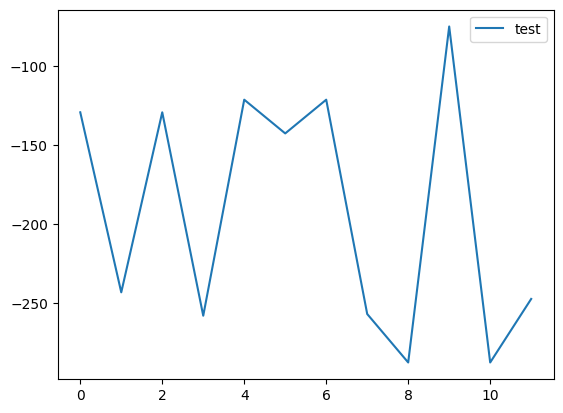

In [84]:
test_scores = clf.cv_results_['mean_test_score']

plt.plot(test_scores, label='test')
plt.legend(loc='best')
plt.show()

In [83]:
clf.cv_results_

{'mean_fit_time': array([ 6.93914492,  0.25385406,  7.15182312,  0.38559186, 43.32587767,
         0.30168526, 39.26214728,  0.40165427, 47.73311374,  0.24901187,
        41.41938624,  0.46426611]),
 'std_fit_time': array([7.62163605e-01, 3.02122523e-02, 7.09969019e-01, 5.35709743e-02,
        2.51062079e+00, 3.06484063e-02, 3.70579833e+00, 3.07529719e-02,
        2.09899614e+01, 1.43224394e-02, 1.52830909e+01, 2.90478098e-02]),
 'mean_score_time': array([0.0197679 , 0.05758801, 0.0171494 , 0.07017174, 0.01778972,
        0.06168532, 0.01692622, 0.07498689, 0.01879513, 0.05314605,
        0.01177483, 0.07235553]),
 'std_score_time': array([0.00686962, 0.01089214, 0.00365672, 0.00614895, 0.00597727,
        0.00501257, 0.00490165, 0.01751904, 0.00947418, 0.00437979,
        0.00553003, 0.01112395]),
 'param_C': masked_array(data=[0.1, 0.1, 0.1, 0.1, 1, 1, 1, 1, 10, 10, 10, 10],
              mask=[False, False, False, False, False, False, False, False,
                    False, False, 

In [85]:
# Define the XGBRegressor model
xgb = XGBRegressor(objective='reg:squarederror', random_state=42)

# Define the parameter grid for GridSearchCV
param_grid = {
    'n_estimators': [50, 100, 300, 500],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7, 10],
    'gamma': [0, 0.1, 0.3],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# Set up GridSearchCV with 10-fold cross-validation
grid_search = GridSearchCV(estimator=xgb, param_grid=param_grid, cv=10, n_jobs=-1, scoring='neg_mean_squared_error')

# Fit the GridSearchCV to the training data
clf = grid_search.fit(X_train, y_train)

# Print the best parameters and best score
print("Best Parameters:", grid_search.best_params_)
print("Best Score:", -grid_search.best_score_)  # Note: GridSearchCV by default uses negative MSE

Best Parameters: {'colsample_bytree': 0.8, 'gamma': 0.3, 'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 500, 'subsample': 0.8}
Best Score: 13.880396226482635


In [ ]:
test_scores = clf.cv_results_['mean_test_score']
train_scores = clf.cv_results_['mean_train_score'] 

plt.plot(test_scores, label='test')
plt.plot(train_scores, label='train')
plt.legend(loc='best')
plt.show()